# Notebook 07 - Analysis

Builds `results/all.csv` (one tidy table with every platform: ideal, QPU, noise model, random, greedy),
then the figures F1–F7 that answer the five research questions.

**Run order:** top to bottom (*Restart* + *Run All* is safe: nothing here uses the QPU).
The noisy simulation itself runs in `07b_noisy_simulation.ipynb`; this notebook only reads its result.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import json
import os
from math import comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from qiskit import qpy
from qiskit.quantum_info import Statevector

from src.graphs import load_instances, find_instance, json_to_graph
from src.hamiltonians import max_cut_hamiltonian
from src.qaoa import build_qaoa, all_cuts
from src.metrics import score, metrics_from_counts, bootstrap_metrics
from src.hardware import estimated_success_from_snapshot

instances = load_instances("../data/instances.json")
ideal = pd.read_csv("../results/sim_ideal_warm.csv")     
reference = pd.read_csv("../data/reference.csv")         
manifest = pd.read_csv("../data/qpu/manifest.csv")       
with open("../data/qpu/random_baseline.json") as f:
    random_counts = json.load(f)["counts"]

In [2]:
def add_reference(results, reference, columns):
    """Add the given columns of the reference table (Stage 2) to a table of results,
    matching rows by graph name and problem."""
    # drop old copies of these columns, otherwise the merge creates *_x and *_y
    results = results.drop(columns=columns, errors="ignore")

    merged = results.merge(reference[["name", "problem"] + columns], on=["name", "problem"])

    assert len(merged) == len(results), "the merge changed the number of rows"
    for column in columns:
        assert merged[column].isna().sum() == 0, "missing values in " + column
    return merged


def instance_info(name):
    """graph_type and n from a name like 'regular3_14'."""
    graph_type, n = name.rsplit("_", 1)      # split at the LAST underscore
    return graph_type, int(n)

## 2. The tidy table `all.csv`

### 2a. Ideal simulator: score and the complete-graph check

In [3]:
ideal = add_reference(ideal, reference, ["random_mean"])
print(score(4.5, 6, 3))      # test on the example computed by hand: must be 0.5

ideal["score"] = score(ideal["mean_cut"], ideal["optimum"], ideal["random_mean"])
ideal[["name", "problem", "p", "mean_cut", "optimum", "random_mean", "score"]].head(10)

0.5


,name,problem,p,mean_cut,optimum,random_mean,score
0,ring_6,maxcut,1,4.500000,6,3.0,0.500000
1,ring_6,maxcut,2,5.000000,6,3.0,0.666667
2,ring_6,maxcut,3,5.999978,6,3.0,0.999993
3,ring_6,bisection,1,2.268502,2,3.6,0.832186
4,ring_6,bisection,2,2.301063,2,3.6,0.811835
5,ring_6,bisection,3,2.393185,2,3.6,0.754259
6,grid_6,maxcut,1,5.050979,7,3.5,0.443137
7,grid_6,maxcut,2,5.996679,7,3.5,0.713337
8,grid_6,maxcut,3,6.743662,7,3.5,0.926761
9,grid_6,bisection,1,3.740561,3,4.2,0.382866


### 2b. QPU and random guessing (from counts)

**Bootstrap.** Resampling the 4000 shots of each circuit gives a 95% confidence interval for every metric, including the score.

In [4]:
rows = []

# QPU: the 38 circuits of the main run (the pilot is left out: 1000 shots, duplicates ring_6)
for _, job_row in manifest[manifest["tag"].str.startswith("main")].iterrows():
    with open(job_row["raw"]) as f:
        data = json.load(f)
    for label in data["labels"]:
        name, problem, p_text = label.split("|")
        graph_type, n = instance_info(name)
        metrics = metrics_from_counts(instances, name, problem, data["counts"][label])
        rows.append({"name": name, "graph_type": graph_type, "n": n, "problem": problem,
                     "p": int(p_text[1:]), "platform": "qpu", **metrics})

# random guessing: the 9 QPU instances, both problems; p = 0 = "zero QAOA layers"
for name, counts in random_counts.items():
    graph_type, n = instance_info(name)
    for problem in ["maxcut", "bisection"]:
        metrics = metrics_from_counts(instances, name, problem, counts)
        rows.append({"name": name, "graph_type": graph_type, "n": n, "problem": problem,
                     "p": 0, "platform": "random", **metrics})

measured = pd.DataFrame(rows)
print(measured["platform"].value_counts())

platform
qpu       38
random    18
Name: count, dtype: int64


In [5]:
# Bootstrap: 95% confidence intervals for every measured circuit (QPU and random guessing)
boot_rows = []

def random_mean_of(name, problem):
    """random_mean for one (graph, problem), from the reference table."""
    row = reference[(reference["name"] == name) & (reference["problem"] == problem)]
    return row["random_mean"].iloc[0]

# QPU: the 38 circuits of the main run (same files as above)
for _, job_row in manifest[manifest["tag"].str.startswith("main")].iterrows():
    with open(job_row["raw"]) as f:
        data = json.load(f)
    for label in data["labels"]:
        name, problem, p_text = label.split("|")
        result = bootstrap_metrics(instances, name, problem, data["counts"][label],
                                   random_mean_of(name, problem))
        boot_rows.append({**result, "p": int(p_text[1:]), "platform": "qpu"})

# random guessing: the same 9 instances, both problems
for name, counts in random_counts.items():
    for problem in ["maxcut", "bisection"]:
        result = bootstrap_metrics(instances, name, problem, counts,
                                   random_mean_of(name, problem))
        boot_rows.append({**result, "p": 0, "platform": "random"})

qpu_bootstrap = pd.DataFrame(boot_rows)
qpu_bootstrap.to_csv("../results/qpu_bootstrap.csv", index=False)
print(qpu_bootstrap["platform"].value_counts())
qpu_bootstrap[["name", "problem", "p", "platform", "score", "score_lo", "score_hi"]].head(10)

platform
qpu       38
random    18
Name: count, dtype: int64


,name,problem,p,platform,score,score_lo,score_hi
0,random_6,bisection,1,qpu,0.089736,0.039340,0.139463
1,random_6,bisection,2,qpu,-0.191983,-0.224484,-0.157820
2,random_6,maxcut,1,qpu,0.497250,0.482375,0.512878
3,random_6,maxcut,2,qpu,0.689625,0.674497,0.705128
4,regular3_6,bisection,1,qpu,0.542395,0.524646,0.560891
5,regular3_6,bisection,2,qpu,0.694123,0.671085,0.717350
6,regular3_6,maxcut,1,qpu,0.502400,0.487197,0.517505
7,regular3_6,maxcut,2,qpu,0.691300,0.676395,0.705600
8,ring_6,bisection,1,qpu,0.728235,0.702351,0.755636
9,ring_6,bisection,2,qpu,0.764780,0.741371,0.786512


Check: the fast bootstrap gives exactly the same point estimates as `metrics_from_counts`.

In [6]:
check = measured.merge(qpu_bootstrap, on=["name", "problem", "p", "platform"], suffixes=("", "_boot"))
for col in ["mean_cut", "valid_fraction", "p_optimal"]:
    print(col, np.allclose(check[col], check[col + "_boot"], equal_nan=True))

mean_cut True
valid_fraction True
p_optimal True


In [7]:
row = qpu_bootstrap[(qpu_bootstrap["name"] == "ring_6") & (qpu_bootstrap["problem"] == "maxcut")
                    & (qpu_bootstrap["p"] == 1) & (qpu_bootstrap["platform"] == "qpu")].iloc[0]
print(f"mean_cut  = {row['mean_cut']:.3f}  [{row['mean_cut_lo']:.3f}, {row['mean_cut_hi']:.3f}]")
print(f"score     = {row['score']:.3f}  [{row['score_lo']:.3f}, {row['score_hi']:.3f}]")
print(f"p_optimal = {row['p_optimal']:.3f}  [{row['p_optimal_lo']:.3f}, {row['p_optimal_hi']:.3f}]")

mean_cut  = 4.340  [4.308, 4.372]
score     = 0.447  [0.436, 0.457]
p_optimal = 0.239  [0.226, 0.252]


### 2c. Noise model (read from `07b_noisy_simulation.ipynb`)

In [8]:
NOISY_PATH = "../results/sim_noisy_pittsburgh.json"

if os.path.exists(NOISY_PATH):
    with open(NOISY_PATH) as f:
        noisy_counts = json.load(f)
else:
    noisy_counts = {}
print("noisy simulation:", len(noisy_counts), "of 38 circuits available")

noisy simulation: 38 of 38 circuits available


### 2d. Greedy (classical)

In [9]:
greedy_rows = reference[["name", "problem", "optimum", "greedy"]].copy()
greedy_rows["graph_type"] = greedy_rows["name"].str.rsplit("_", n=1).str[0]
greedy_rows["n"] = greedy_rows["name"].str.rsplit("_", n=1).str[1].astype(int)
greedy_rows["p"] = np.nan                     # not a QAOA method: p does not apply
greedy_rows["platform"] = "greedy"
greedy_rows["mean_cut"] = greedy_rows["greedy"]
greedy_rows["best_sample_cut"] = greedy_rows["greedy"]
greedy_rows["valid_fraction"] = 1.0
greedy_rows["p_optimal"] = (greedy_rows["greedy"] == greedy_rows["optimum"]).astype(float)

print(len(greedy_rows), "greedy rows | found the optimum on", int(greedy_rows["p_optimal"].sum()))

50 greedy rows | found the optimum on 50


### 2e. All platforms in one table, with every metric

In [10]:
COLUMNS = ["name", "graph_type", "n", "problem", "p", "platform",
           "valid_fraction", "mean_cut", "p_optimal", "best_sample_cut", "optimum"]

ideal_rows = ideal.copy()
ideal_rows["platform"] = "ideal"
ideal_rows = ideal_rows[COLUMNS]

# noisy rows: the same processing as for the QPU
noisy_list = []
for label, counts in noisy_counts.items():
    name, problem, p_text = label.split("|")
    graph_type, n = instance_info(name)
    metrics = metrics_from_counts(instances, name, problem, counts)
    noisy_list.append({"name": name, "graph_type": graph_type, "n": n, "problem": problem,
                       "p": int(p_text[1:]), "platform": "noisy", **metrics})
noisy_rows = pd.DataFrame(noisy_list, columns=COLUMNS)    # empty table if not simulated yet

# all platforms, one under the other
parts = [ideal_rows, measured[COLUMNS], greedy_rows[COLUMNS]]
if len(noisy_rows) > 0:
    parts.append(noisy_rows[COLUMNS])
all_results = pd.concat(parts, ignore_index=True)
all_results = add_reference(all_results, reference, ["random_mean", "num_optima"])

# score on the mean and on the best of N samples
all_results["score"] = score(all_results["mean_cut"], all_results["optimum"], all_results["random_mean"])
all_results["score_best"] = score(all_results["best_sample_cut"], all_results["optimum"], all_results["random_mean"])

# improvement factor: P(optimum) relative to random guessing (num_optima / 2^n)
all_results["p_optimal_random"] = all_results["num_optima"] / 2.0 ** all_results["n"]
all_results["improvement"] = all_results["p_optimal"] / all_results["p_optimal_random"]

# balanced-fraction improvement (bisection only): relative to random, C(n, n/2) / 2^n
balanced_random = all_results["n"].apply(lambda n: comb(n, n // 2)) / 2.0 ** all_results["n"]
all_results["valid_improvement"] = np.where(all_results["problem"] == "bisection",
                                            all_results["valid_fraction"] / balanced_random, np.nan)

all_results.to_csv("../results/all.csv", index=False)
print(len(all_results), "rows")
all_results["platform"].value_counts()

294 rows


platform
ideal     150
greedy     50
qpu        38
noisy      38
random     18
Name: count, dtype: int64

In [11]:
# sanity check: random guessing must score ~0 (within about ±0.03)
all_results[all_results["platform"] == "random"][["name", "problem", "mean_cut", "random_mean", "score"]]

,name,problem,mean_cut,random_mean,score
188,random_10,maxcut,9.940500,10.000000,-0.011900
189,random_10,bisection,11.100735,11.111111,0.002524
190,random_14,maxcut,22.545000,22.500000,0.004737
191,random_14,bisection,24.139194,24.230769,0.011126
192,random_6,maxcut,3.978750,4.000000,-0.010625
193,random_6,bisection,4.777500,4.800000,0.028125
194,regular3_10,maxcut,7.451750,7.500000,-0.008773
195,regular3_10,bisection,8.330435,8.333333,0.000543
196,regular3_14,maxcut,10.493750,10.500000,-0.000962
197,regular3_14,bisection,11.333733,11.307692,-0.003135


In [12]:
# expected: ideal 15 and greedy 5 (complete graphs, bisection: S = 0/0)
nan_rows = all_results[all_results["score"].isna()]
print(nan_rows.groupby(["platform", "graph_type", "problem"]).size())

platform  graph_type  problem  
greedy    complete    bisection     5
ideal     complete    bisection    15
dtype: int64


## 3. F1 / Q1 — ideal quality vs. p
**Q1.** Without noise, how close does QAOA get to the optimum, and does it improve with more layers?

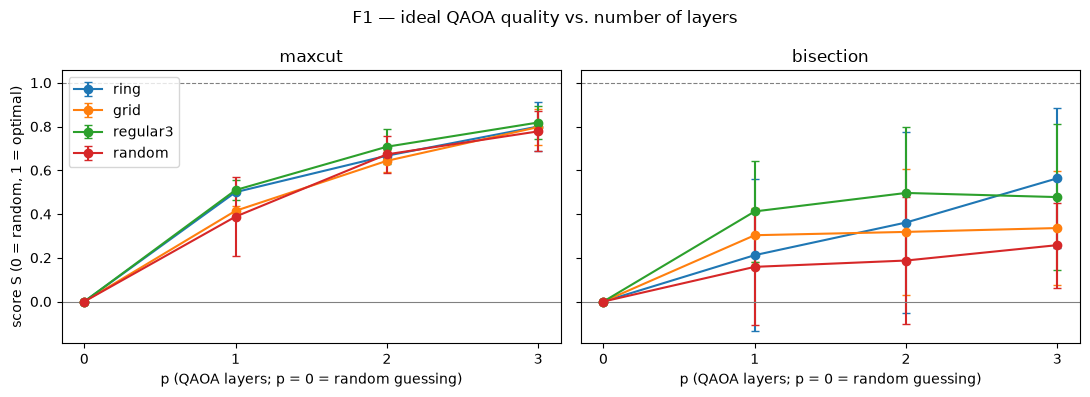

In [13]:
all_results = pd.read_csv("../results/all.csv")

# ideal rows, without the complete graphs (S undefined for bisection)
data = all_results[(all_results["platform"] == "ideal") & (all_results["graph_type"] != "complete")]

# mean and spread of the score over the 5 sizes n, for each problem, graph type and p
summary = data.groupby(["problem", "graph_type", "p"])["score"].agg(["mean", "std"]).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, problem in zip(axes, ["maxcut", "bisection"]):
    part = summary[summary["problem"] == problem]
    for graph_type in ["ring", "grid", "regular3", "random"]:
        g = part[part["graph_type"] == graph_type]
        # p = 0 (random guessing, S = 0 by definition), then p = 1, 2, 3
        ps = [0] + g["p"].tolist()
        means = [0] + g["mean"].tolist()
        stds = [0] + g["std"].tolist()
        ax.errorbar(ps, means, yerr=stds, marker="o", capsize=3, label=graph_type)

    ax.set_title(problem)
    ax.set_xlabel("p (QAOA layers; p = 0 = random guessing)")
    ax.set_xticks([0, 1, 2, 3])
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")

axes[0].set_ylabel("score S (0 = random, 1 = optimal)")
axes[0].legend()
fig.suptitle("F1 — ideal QAOA quality vs. number of layers")
plt.tight_layout()
plt.savefig("../figures/F1_ideal_score_vs_p.png", dpi=150)
plt.show()

**Interpretation.** On Max-Cut the score rises steadily with p for every graph type (≈ 0.4–0.5 at p = 1 → ≈ 0.8 at p = 3), with small spread across sizes.
On bisection it stays lower (0.16–0.56 at p = 3), varies a lot between sizes (wide bars), and does not always improve with p (regular3: 0.50 → 0.48).
The energy never increases with p (checked in 04), but the energy also contains the penalty term: the optimizer can lower it by balancing
more partitions without improving their cut. The penalty makes bisection a harder landscape for QAOA.

## 4. F2 / Q2 — ideal vs. noise model vs. QPU
**Q2.** How much of the ideal quality survives on real hardware, and how much of the loss does a calibration-based noise model explain?

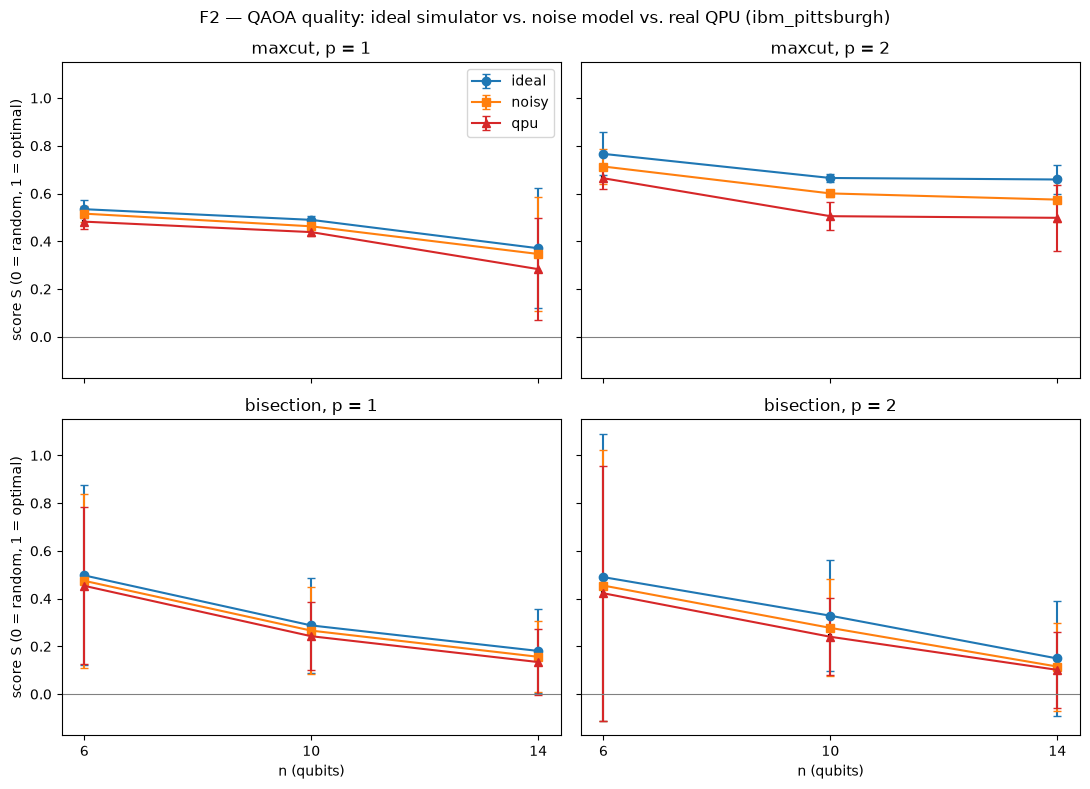

In [14]:
all_results = pd.read_csv("../results/all.csv")

# the 9 instances that ran on the QPU
qpu_names = all_results[all_results["platform"] == "qpu"]["name"].unique()

data = all_results[
    all_results["platform"].isin(["ideal", "noisy", "qpu"])
    & all_results["name"].isin(qpu_names)          # the same instances on every platform
    & all_results["p"].isin([1, 2])                # without the p = 3 stress tests
]

# mean and spread over the 3 graph types, for each problem, p, platform and n
summary = data.groupby(["problem", "p", "platform", "n"])["score"].agg(["mean", "std"]).reset_index()

# bootstrap: shot-noise uncertainty of the QPU mean (main run only)
boot = pd.read_csv("../results/qpu_bootstrap.csv")
boot = boot[(boot["platform"] == "qpu") & (boot.get("run", "main") == "main")].copy()
boot["n"] = boot["name"].str.rsplit("_", n=1).str[1].astype(int)   # "regular3_14" -> 14
boot["half"] = (boot["score_hi"] - boot["score_lo"]) / 2
# the mean of k independent estimates: half-width = sqrt(sum of half-widths^2) / k
boot_ci = (boot.groupby(["problem", "p", "n"])["half"]
               .apply(lambda h: np.sqrt((h ** 2).sum()) / len(h)).reset_index())

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
styles = {"ideal": ("C0", "o"), "noisy": ("C1", "s"), "qpu": ("C3", "^")}

for row, problem in enumerate(["maxcut", "bisection"]):
    for col, p in enumerate([1, 2]):
        ax = axes[row, col]
        for platform, (color, marker) in styles.items():
            g = summary[(summary["problem"] == problem) & (summary["p"] == p)
                        & (summary["platform"] == platform)]
            ax.errorbar(g["n"], g["mean"], yerr=g["std"], color=color, marker=marker,
                        capsize=3, label=platform)
            if platform == "qpu":
                ci = boot_ci[(boot_ci["problem"] == problem) & (boot_ci["p"] == p)].set_index("n")["half"]
                ax.errorbar(g["n"], g["mean"], yerr=ci.reindex(g["n"]).values,
                            fmt="none", ecolor="black", elinewidth=3, capsize=0)
                            
        ax.set_title(problem + ", p = " + str(p))
        ax.axhline(0, color="gray", linewidth=0.8)
        ax.set_xticks([6, 10, 14])

for ax in axes[1]:
    ax.set_xlabel("n (qubits)")
for ax in axes[:, 0]:
    ax.set_ylabel("score S (0 = random, 1 = optimal)")
axes[0, 0].legend()
fig.suptitle("F2 — QAOA quality: ideal simulator vs. noise model vs. real QPU (ibm_pittsburgh)")
plt.tight_layout()
plt.savefig("../figures/F2_score_vs_n_platforms.png", dpi=150)
plt.show()

**Interpretation.** The QPU is below the ideal simulator everywhere, and all scores fall with n. The loss is larger at p = 2 (0.05–0.16) than at p = 1 (0.04–0.09),
but on Max-Cut the second layer is still worth its noise: on the QPU, p = 2 beats p = 1 at every size (e.g. 0.50 vs. 0.28 at n = 14).
On bisection it is not (0.10–0.42 at p = 2 vs. 0.13–0.45 at p = 1).
Thin bars: spread over the 3 graph types. The 95% bootstrap CIs from shot noise (±0.01 or less) are smaller than the markers,
so the gaps between platforms are not a sampling effect.

In [15]:
pivot = data.pivot_table(index=["problem", "p", "n"], columns="platform", values="score", aggfunc="mean")
pivot["loss_total"] = pivot["ideal"] - pivot["qpu"]              # ideal -> QPU

if "noisy" in pivot.columns:                                     # only after the noisy simulation
    pivot["loss_model"] = pivot["ideal"] - pivot["noisy"]        # explained by the noise model
    pivot["loss_unexplained"] = pivot["noisy"] - pivot["qpu"]    # what the model misses

pivot.round(3)

platform          ideal  noisy    qpu  loss_total  loss_model  \
problem   p   n                                                 
bisection 1.0 6   0.497  0.474  0.453       0.044       0.023   
              10  0.288  0.266  0.242       0.045       0.022   
              14  0.181  0.156  0.134       0.047       0.025   
          2.0 6   0.490  0.455  0.422       0.068       0.035   
              10  0.328  0.277  0.240       0.088       0.051   
              14  0.149  0.115  0.101       0.048       0.034   
maxcut    1.0 6   0.534  0.516  0.482       0.052       0.019   
              10  0.490  0.463  0.438       0.051       0.027   
              14  0.371  0.347  0.283       0.088       0.024   
          2.0 6   0.766  0.713  0.664       0.102       0.053   
              10  0.665  0.600  0.505       0.160       0.065   
              14  0.659  0.574  0.498       0.161       0.084   

platform          loss_unexplained  
problem   p   n                     
bisection 1.0 6              0.021  
              10             0.023  
              14             0.022  
          2.0 6              0.032  
              10             0.037  
              14             0.014  
maxcut    1.0 6              0.033  
              10             0.024  
              14             0.063  
          2.0 6              0.049  
              10             0.095  
              14             0.076

## 5. F3 / Q3 — QPU vs. random guessing
**Q3.** On the QPU, does QAOA find the optimal partition more often than random guessing?

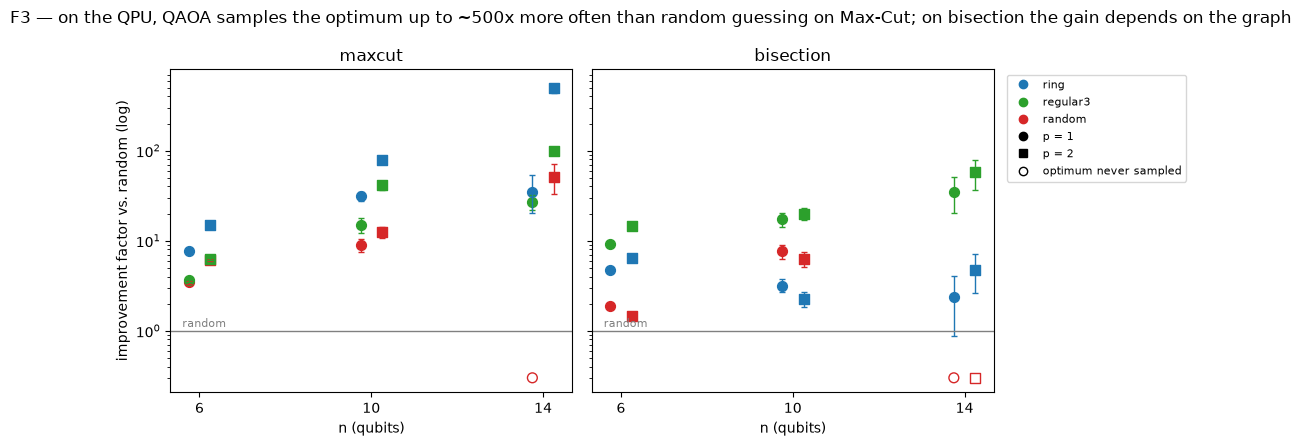

In [16]:
all_results = pd.read_csv("../results/all.csv")

qpu = all_results[(all_results["platform"] == "qpu") & (all_results["p"].isin([1, 2]))]

boot = pd.read_csv("../results/qpu_bootstrap.csv")
boot = boot[(boot["platform"] == "qpu") & (boot.get("run", "main") == "main")]
qpu = qpu.astype({"p": int}).merge(boot[["name", "problem", "p", "p_optimal_lo", "p_optimal_hi"]],
                                   on=["name", "problem", "p"])
qpu["improvement_lo"] = qpu["p_optimal_lo"] / qpu["p_optimal_random"]
qpu["improvement_hi"] = qpu["p_optimal_hi"] / qpu["p_optimal_random"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
colors = {"ring": "C0", "regular3": "C2", "random": "C3"}
markers = {1: "o", 2: "s"}
FLOOR = 0.3                       # where the "never found" points are drawn

for ax, problem in zip(axes, ["maxcut", "bisection"]):
    part = qpu[qpu["problem"] == problem]
    for _, r in part.iterrows():
        found = r["improvement"] > 0
        y = r["improvement"] if found else FLOOR
        # a small horizontal shift for p, so the two points at the same n do not overlap
        x = r["n"] + (-0.25 if r["p"] == 1 else 0.25)
        ax.scatter(x, y, color=colors[r["graph_type"]], marker=markers[r["p"]],
                   facecolors=colors[r["graph_type"]] if found else "none", s=50)
        if found:
            lo = max(r["improvement_lo"], FLOOR)      # log scale: 0 cannot be drawn
            ax.errorbar(x, y, yerr=[[y - lo], [r["improvement_hi"] - y]],
                        fmt="none", ecolor=colors[r["graph_type"]], capsize=2, linewidth=1)

    ax.axhline(1, color="gray", linewidth=1)
    ax.text(5.6, 1.1, "random", color="gray", fontsize=8, ha="left")
    ax.set_yscale("log")
    ax.set_title(problem)
    ax.set_xticks([6, 10, 14])
    ax.set_xlabel("n (qubits)")

axes[0].set_ylabel("improvement factor vs. random (log)")

# legend built by hand: colors = graph type, shapes = p, empty marker = never found
handles = [Line2D([], [], color=c, marker="o", linestyle="", label=t) for t, c in colors.items()]
handles += [Line2D([], [], color="black", marker=m, linestyle="", label="p = " + str(p)) for p, m in markers.items()]
handles += [Line2D([], [], color="black", marker="o", markerfacecolor="none", linestyle="",
                   label="optimum never sampled")]

axes[1].legend(handles=handles, fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("F3 — on the QPU, QAOA samples the optimum up to ~500x more often than random guessing "
                "on Max-Cut; on bisection the gain depends on the graph")
plt.tight_layout()
plt.savefig("../figures/F3_improvement_qpu.png", dpi=150)
plt.show()

**Interpretation.** Improvement factor = P_QPU(optimum) / P_random(optimum). On Max-Cut the QPU samples the optimum 3–500× more often than random guessing,
and the factor grows with n, because random guessing becomes hopeless faster than QAOA does. On bisection the gain depends on the graph:
large on regular3 (35–57× at n = 14), small on ring (2–5×), and random_14 never sampled the optimum.
Error bars: 95% bootstrap CIs; they are long at n = 14, where the optimum appeared only a few times in 4000 shots.

In [17]:
table = qpu[["name", "problem", "p", "p_optimal", "p_optimal_random", "improvement", "score"]]
table.sort_values(["problem", "name", "p"]).round(4)

,name,problem,p,p_optimal,p_optimal_random,improvement,score
12,random_10,bisection,1,0.0298,0.0039,7.6160,0.2991
13,random_10,bisection,2,0.0248,0.0039,6.3360,0.3392
24,random_14,bisection,1,0.0000,0.0001,0.0000,0.0956
25,random_14,bisection,2,0.0000,0.0001,0.0000,-0.0119
0,random_6,bisection,1,0.2372,0.1250,1.8980,0.0897
1,random_6,bisection,2,0.1802,0.1250,1.4420,-0.1920
16,regular3_10,bisection,1,0.0340,0.0020,17.4080,0.3483
17,regular3_10,bisection,2,0.0388,0.0020,19.8400,0.3260
28,regular3_14,bisection,1,0.0042,0.0001,34.8160,0.2859
29,regular3_14,bisection,2,0.0070,0.0001,57.3440,0.2817


### Which conclusions survive the bootstrap?

In [18]:
boot = pd.read_csv("../results/qpu_bootstrap.csv")
boot = boot[(boot["platform"] == "qpu") & (boot.get("run", "main") == "main")].copy()
boot["n"] = boot["name"].str.rsplit("_", n=1).str[1].astype(int)

# 1) bisection at n = 14: is the score significantly above random guessing (S = 0)?
b14 = boot[(boot["problem"] == "bisection") & (boot["n"] == 14)]
b14 = b14[["name", "p", "score", "score_lo", "score_hi"]].copy()
b14["above_random"] = b14["score_lo"] > 0
print(b14.round(3).to_string(index=False))

# 2) random_10 Max-Cut: is p = 2 really better than p = 1?
#    two independent estimates -> CI of the difference ≈ sqrt(h1^2 + h2^2)
r = boot[(boot["name"] == "random_10") & (boot["problem"] == "maxcut")].set_index("p")
diff = r.loc[2, "score"] - r.loc[1, "score"]
half = np.sqrt(((r.loc[1, "score_hi"] - r.loc[1, "score_lo"]) / 2) ** 2
               + ((r.loc[2, "score_hi"] - r.loc[2, "score_lo"]) / 2) ** 2)
print(f"\nrandom_10 Max-Cut: S(p=2) - S(p=1) = {diff:.3f}  95% CI [{diff - half:.3f}, {diff + half:.3f}]",
      "-> real difference" if abs(diff) > half else "-> not significant")

       name  p  score  score_lo  score_hi  above_random
  random_14  1  0.096     0.079     0.111          True
  random_14  2 -0.012    -0.029     0.004         False
regular3_14  1  0.286     0.270     0.300          True
regular3_14  2  0.282     0.265     0.299          True
    ring_14  1  0.021     0.005     0.037          True
    ring_14  2  0.035     0.020     0.048          True
regular3_14  3  0.006    -0.008     0.021         False
  random_14  3 -0.007    -0.025     0.010         False

random_10 Max-Cut: S(p=2) - S(p=1) = 0.014  95% CI [-0.002, 0.030] -> not significant


## 6. F4 / Q4 — all methods side by side
**Q4.** How does QAOA on the QPU compare with the classical methods: random guessing and greedy?

In [19]:
all_results = pd.read_csv("../results/all.csv")
qpu_names = all_results[all_results["platform"] == "qpu"]["name"].unique()

# one value per (instance, problem) for each method
def column(platform, metric, p=None):
    rows = all_results[(all_results["platform"] == platform) & all_results["name"].isin(qpu_names)]
    if p is not None:
        rows = rows[rows["p"] == p]
    return rows.set_index(["name", "problem"])[metric]

f4 = reference[reference["name"].isin(qpu_names)].set_index(["name", "problem"])[["optimum", "greedy"]].copy()

f4["random_mean"] = column("random", "mean_cut")
f4["ideal_mean"] = column("ideal", "mean_cut", p=2)
f4["qpu_mean"] = column("qpu", "mean_cut", p=2)

f4["random_best"] = column("random", "best_sample_cut")
f4["qpu_best"] = column("qpu", "best_sample_cut", p=2)

f4 = f4.sort_index(level=["problem", "name"])
f4.round(2)

,,optimum,greedy,random_mean,ideal_mean,qpu_mean,random_best,qpu_best
name,problem,,,,,,,
random_10,bisection,7,7,11.10,9.15,9.72,7.0,7.0
random_14,bisection,16,16,24.14,24.46,24.33,18.0,18.0
random_6,bisection,4,4,4.78,4.96,4.95,4.0,4.0
regular3_10,bisection,3,3,8.33,5.95,6.59,3.0,3.0
regular3_14,bisection,3,3,11.33,7.79,8.97,5.0,3.0
regular3_6,bisection,3,3,5.44,3.33,3.73,3.0,3.0
ring_10,bisection,2,2,5.49,5.34,5.36,2.0,2.0
ring_14,bisection,2,2,7.41,7.25,7.35,2.0,2.0
ring_6,bisection,2,2,3.58,2.30,2.38,2.0,2.0


In [20]:
f4["random_found"] = f4["random_best"] == f4["optimum"]
f4["qpu_found"] = f4["qpu_best"] == f4["optimum"]
print("random found the optimum in", f4["random_found"].sum(), "of", len(f4))
print("QPU (p = 2) found the optimum in", f4["qpu_found"].sum(), "of", len(f4))
f4[["optimum", "random_best", "qpu_best", "random_found", "qpu_found"]]

random found the optimum in 14 of 18
QPU (p = 2) found the optimum in 17 of 18


,,optimum,random_best,qpu_best,random_found,qpu_found
name,problem,,,,,
random_10,bisection,7,7.0,7.0,True,True
random_14,bisection,16,18.0,18.0,False,False
random_6,bisection,4,4.0,4.0,True,True
regular3_10,bisection,3,3.0,3.0,True,True
regular3_14,bisection,3,5.0,3.0,False,True
regular3_6,bisection,3,3.0,3.0,True,True
ring_10,bisection,2,2.0,2.0,True,True
ring_14,bisection,2,2.0,2.0,True,True
ring_6,bisection,2,2.0,2.0,True,True


**Interpretation.** On average, QAOA on the QPU (p = 2) lies between random guessing and the ideal simulator.
Taking the best of 4000 shots, the QPU found the optimum on 17 of 18 instance/problem pairs, random guessing on 14 of 18,
and greedy on all 18. At n ≤ 14 a simple classical heuristic is still better: the value of this experiment is measuring
how QAOA behaves and degrades on real hardware, not a quantum advantage.

## 7. F5 / Q5 — Max-Cut vs. bisection on the same graphs
**Q5.** On the same graph, how much harder is bisection than Max-Cut on real hardware?

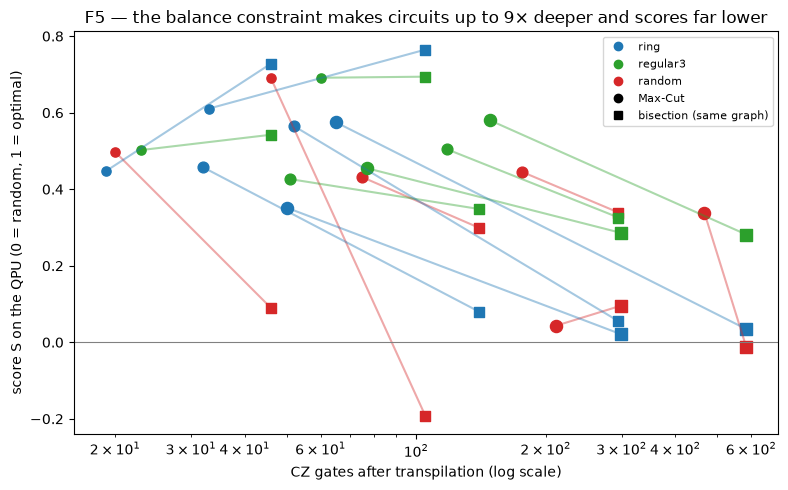

In [21]:
transp = pd.read_csv("../results/transpilation_ibm_boston.csv")[["name", "problem", "p", "cz_count"]]
qpu = all_results[(all_results["platform"] == "qpu") & all_results["p"].isin([1, 2])].astype({"p": int})
f5 = qpu.merge(transp, on=["name", "problem", "p"])

fig, ax = plt.subplots(figsize=(8, 5))
colors = {"ring": "C0", "regular3": "C2", "random": "C3"}
for (name, p), g in f5.groupby(["name", "p"]):
    mc = g[g["problem"] == "maxcut"].iloc[0]
    bi = g[g["problem"] == "bisection"].iloc[0]
    c = colors[mc["graph_type"]]
    ax.plot([mc["cz_count"], bi["cz_count"]], [mc["score"], bi["score"]], color=c, alpha=0.4)
    ax.scatter(mc["cz_count"], mc["score"], color=c, marker="o", s=20 + 4 * mc["n"])
    ax.scatter(bi["cz_count"], bi["score"], color=c, marker="s", s=20 + 4 * bi["n"])

ax.set_xscale("log")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("CZ gates after transpilation (log scale)")
ax.set_ylabel("score S on the QPU (0 = random, 1 = optimal)")
handles = [Line2D([], [], color=c, marker="o", linestyle="", label=t) for t, c in colors.items()]
handles += [Line2D([], [], color="black", marker="o", linestyle="", label="Max-Cut"),
            Line2D([], [], color="black", marker="s", linestyle="", label="bisection (same graph)")]
ax.legend(handles=handles, fontsize=8)
ax.set_title("F5 — the balance constraint makes circuits up to 9× deeper and scores far lower")
plt.tight_layout()
plt.savefig("../figures/F5_maxcut_vs_bisection_qpu.png", dpi=150)
plt.show()

**Interpretation.** Each line joins Max-Cut (circle) and bisection (square) on the same graph and p. Bisection always sits to the right
(4–9× more CZ gates, because the penalty couples every pair of qubits) and lower (much smaller score).
The balance constraint, not the graph itself, is what makes bisection expensive on hardware.

## 8. F6 — one instance, three distributions

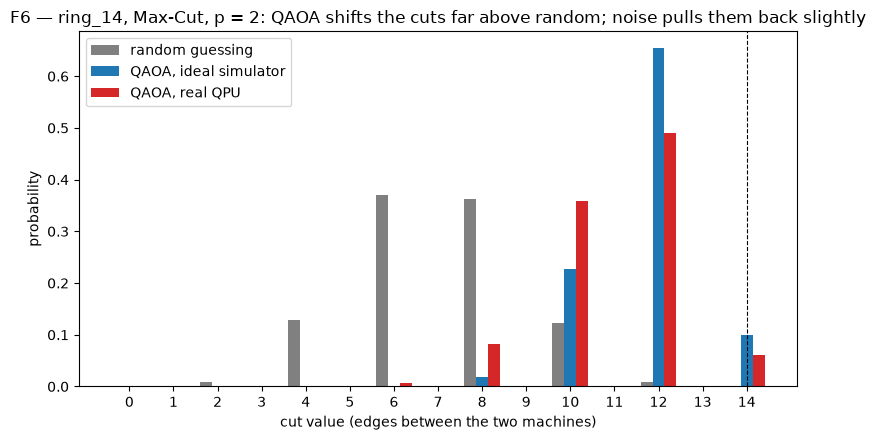

In [22]:
NAME, PROBLEM, P = "ring_14", "maxcut", 2
graph = json_to_graph(find_instance(instances, NAME))
cuts = all_cuts(graph)                            # cut value of every bitstring, index = integer
max_cut_value = int(cuts.max())

def cut_distribution_from_counts(counts):
    """Probability of each cut value, from counts {bitstring: number}."""
    dist = np.zeros(max_cut_value + 1)
    total = sum(counts.values())
    for bitstring, count in counts.items():
        dist[int(cuts[int(bitstring, 2)])] += count / total
    return dist

# ideal: exact probabilities from the optimized angles
with open("../results/params_warm.json") as f:
    rows_warm = json.load(f)
params = [r for r in rows_warm if r["name"] == NAME and r["problem"] == PROBLEM and r["p"] == P][0]["params"]
probabilities = Statevector(build_qaoa(max_cut_hamiltonian(graph), P).assign_parameters(params)).probabilities()
ideal_dist = np.bincount(cuts.astype(int), weights=probabilities, minlength=max_cut_value + 1)

# QPU and random: from the saved counts
job_row = manifest[manifest["tag"] == "main_n14"].iloc[0]
with open(job_row["raw"]) as f:
    qpu_dist = cut_distribution_from_counts(json.load(f)["counts"][NAME + "|" + PROBLEM + "|p" + str(P)])
random_dist = cut_distribution_from_counts(random_counts[NAME])

x = np.arange(max_cut_value + 1)
width = 0.27
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width, random_dist, width, color="gray", label="random guessing")
ax.bar(x, ideal_dist, width, color="C0", label="QAOA, ideal simulator")
ax.bar(x + width, qpu_dist, width, color="C3", label="QAOA, real QPU")
ax.axvline(max_cut_value, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("cut value (edges between the two machines)")
ax.set_ylabel("probability")
ax.set_xticks(x)
ax.legend()
ax.set_title("F6 — ring_14, Max-Cut, p = 2: QAOA shifts the cuts far above random; noise pulls them back slightly")
plt.tight_layout()
plt.savefig("../figures/F6_histogram_ring14.png", dpi=150)
plt.show()

**Interpretation.** On ring_14 (Max-Cut, p = 2) random guessing cuts about 7 of 14 edges on average. Ideal QAOA moves the distribution
to an average of 11.7 and the QPU keeps most of that shift (11.0): noise pulls the distribution slightly back towards random,
but the effect of QAOA is clearly visible on real hardware.

## 9. F7 — does ESP predict the QPU result?

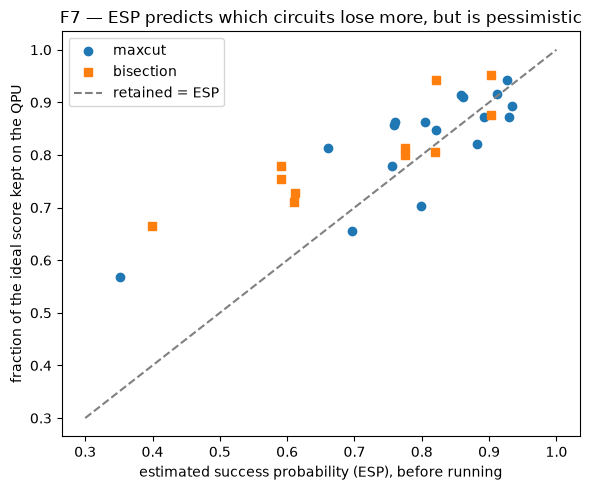

correlation: 0.84 | circuits: 28


In [23]:
with open("../data/qpu/calibration/ibm_pittsburgh_2026-10-27T15-02.json") as f:
    snapshot = json.load(f)

esp = {}
for _, job_row in manifest[manifest["tag"].str.startswith("main")].iterrows():
    with open(job_row["circuits"], "rb") as f:
        circuits = qpy.load(f)
    with open(job_row["raw"]) as f:
        labels = json.load(f)["labels"]
    for label, circuit in zip(labels, circuits):
        esp[label] = estimated_success_from_snapshot(circuit, snapshot)

key = ["name", "problem", "p"]
q = all_results[(all_results["platform"] == "qpu") & all_results["p"].isin([1, 2])].set_index(key)
i = all_results[all_results["platform"] == "ideal"].set_index(key)
f7 = q[["score"]].rename(columns={"score": "score_qpu"})
f7["score_ideal"] = i["score"]
f7 = f7.reset_index()
f7["esp"] = [esp[n + "|" + pr + "|p" + str(int(p))] for n, pr, p in zip(f7["name"], f7["problem"], f7["p"])]
f7 = f7[f7["score_ideal"] > 0.1]
f7["retained"] = f7["score_qpu"] / f7["score_ideal"]

fig, ax = plt.subplots(figsize=(6, 5))
for problem, marker in [("maxcut", "o"), ("bisection", "s")]:
    g = f7[f7["problem"] == problem]
    ax.scatter(g["esp"], g["retained"], marker=marker, label=problem)
ax.plot([0.3, 1], [0.3, 1], color="gray", linestyle="--", label="retained = ESP")
ax.set_xlabel("estimated success probability (ESP), before running")
ax.set_ylabel("fraction of the ideal score kept on the QPU")
ax.legend()
ax.set_title("F7 — ESP predicts which circuits lose more, but is pessimistic")
plt.tight_layout()
plt.savefig("../figures/F7_retained_vs_esp.png", dpi=150)
plt.show()

print("correlation:", round(np.corrcoef(f7["esp"], f7["retained"])[0, 1], 2), "| circuits:", len(f7))

**Interpretation.** Almost all circuits lie above the diagonal: they keep more of their ideal score than ESP predicts, so ESP is pessimistic.
It still ranks them well (correlation 0.84 over 28 circuits): ESP, computed before running, tells which circuits will suffer more,
but not by how much. Together with the noise model (optimistic, Q2), it brackets the real result.

## 10. Predictions (Stage 5) vs. results

In [24]:
pred = pd.read_csv("../data/qpu/circuit_list_2026-10-26.csv")[["name", "problem", "p", "prediction"]]
qpu = all_results[all_results["platform"] == "qpu"][["name", "problem", "p", "score"]].astype({"p": int})
check = pred.merge(qpu, on=["name", "problem", "p"])

def outcome(score):
    """The same three categories as the prediction, from the real QPU score."""
    if score < 0.05:          # within the statistical noise of random guessing (±0.03)
        return "fail"
    if score > 0.4:
        return "works"
    return "weak"

check["outcome"] = check["score"].apply(outcome)
print("correct predictions:", (check["prediction"] == check["outcome"]).sum(), "of", len(check))
pd.crosstab(check["prediction"], check["outcome"])

correct predictions: 29 of 38


outcome,fail,weak,works
prediction,,,
fail,7,4,0
weak,0,6,3
works,0,2,16


In [25]:
# the 9 wrong predictions: do they have something in common?
check[check["prediction"] != check["outcome"]].sort_values(["prediction", "outcome"])

,name,problem,p,prediction,score,outcome
0,random_6,bisection,1,fail,0.089736,weak
20,ring_10,bisection,1,fail,0.079933,weak
21,ring_10,bisection,2,fail,0.055043,weak
24,random_14,bisection,1,fail,0.095629,weak
15,random_10,maxcut,2,weak,0.445500,works
31,regular3_14,maxcut,2,weak,0.580615,works
35,ring_14,maxcut,2,weak,0.575357,works
16,regular3_10,bisection,1,works,0.348269,weak
34,ring_14,maxcut,1,works,0.351857,weak


**Interpretation.** 29 of 38 predictions were correct. 7 of the 9 errors were pessimistic (the circuit did better than predicted),
mostly bisection circuits predicted to fail that reached a weak score. This matches F7: the ESP-based rule underestimates the hardware.

## 11. Day-to-day variability (repeat run, 28 Oct)
The same three circuits (n = 6, 10, 14) were run again one day later; are the differences larger than the bootstrap noise?

In [26]:
# The same 3 circuits on two days: score with 95% bootstrap CI, and whether the change is real
def counts_for(tag_filter, label):
    """Counts of one circuit from the QPU jobs selected by tag_filter."""
    for _, job_row in manifest[tag_filter].iterrows():
        with open(job_row["raw"]) as f:
            data = json.load(f)
        if label in data["counts"]:
            return data["counts"][label]

with open("../data/qpu/raw/" + manifest[manifest["tag"] == "repeat"].iloc[0]["job_id"] + ".json") as f:
    repeat_labels = json.load(f)["labels"]

rows = []
for label in repeat_labels:
    name, problem, p_text = label.split("|")
    rm = reference[(reference["name"] == name) & (reference["problem"] == problem)]["random_mean"].iloc[0]
    day1 = bootstrap_metrics(instances, name, problem,
                             counts_for(manifest["tag"].str.startswith("main"), label), rm)
    day2 = bootstrap_metrics(instances, name, problem,
                             counts_for(manifest["tag"] == "repeat", label), rm)
    diff = day2["score"] - day1["score"]
    half = np.sqrt(((day1["score_hi"] - day1["score_lo"]) / 2) ** 2
                   + ((day2["score_hi"] - day2["score_lo"]) / 2) ** 2)
    rows.append({"circuit": label,
                 "S_day1": day1["score"], "S_day1_CI": (round(day1["score_lo"], 3), round(day1["score_hi"], 3)),
                 "S_day2": day2["score"], "S_day2_CI": (round(day2["score_lo"], 3), round(day2["score_hi"], 3)),
                 "difference": diff, "real_change": abs(diff) > half})

variability = pd.DataFrame(rows)
variability.round(3)

,circuit,S_day1,S_day1_CI,S_day2,S_day2_CI,difference,real_change
0,ring_6|maxcut|p1,0.447,"(0.436, 0.457)",0.467,"(0.456, 0.477)",0.020,True
1,regular3_10|bisection|p1,0.348,"(0.33, 0.365)",0.353,"(0.336, 0.368)",0.005,False
2,random_14|maxcut|p1,0.043,"(0.033, 0.052)",0.036,"(0.027, 0.046)",-0.007,False
